# Do plant stem-cell (meristem) genes respond to spaceflight? A re-analysis of NASA open data
**Riddhika D** · Space Botany project · v2.3 (real data)

**Data:** NASA Open Science Data Repository (OSDR / GeneLab). Every *Arabidopsis thaliana* RNA-seq study with a **spaceflight vs ground-control** factor that has GeneLab's standard processed results (`differential_expression_GLbulkRNAseq.csv`). The notebook finds the studies automatically; nothing is typed in by hand.

### Decided before looking at results
| | |
|---|---|
| **Primary question** | Do **root stem-cell niche** genes (PLT1/2/3, BBM, WOX5, SCR, SHR, CLE40, ACR4) change more under spaceflight than random genes? |
| **Secondary** | Shoot meristem set (WUS, CLV1, CLV3, STM); auxin transport set (PIN1/2/3/4/7, AUX1, LAX3) |
| **Positive control** | The 5 genes Paul et al. 2013 confirmed by RT-qPCR in three flights: DDF1, DREB2A, TCH4, JAZ7, ELIP1. They **should** score high. If they do not, the method is not trusted |
| **Contrasts used** | Only flight-vs-ground pairs where every other factor (genotype, tissue, light, age) is the same |
| **Score** | Per gene: signed z from GeneLab's p-value and fold-change direction. Per set: mean \|z\| |
| **Null** | 10,000 random gene sets of the same size, matched on mean expression |
| **Verdict rule** | A set "responds" in an experiment if empirical p < 0.05 in at least half of its contrasts; overall claim needs ≥ 2 independent experiments. (v2.3: re-processed copies of the same flight are detected and merged, see 3b) |

Run: **Runtime → Run all** (5–15 minutes; downloads a few CSV files from NASA). Copy the **SEND THIS TO CLAUDE** box at the end.

In [1]:
import io, re, json, requests, time
import numpy as np, pandas as pd
from scipy import stats
REPORT = []
def note(s): print(s); REPORT.append(str(s))
BASE = 'https://osdr.nasa.gov'
S = requests.Session(); S.headers['User-Agent'] = 'colab-research-notebook'

def get(url, **kw):
    for i in range(3):
        try:
            r = S.get(url, timeout=180, **kw); r.raise_for_status(); return r
        except Exception as e:
            print('  retry', i + 1, url[:90], str(e)[:80]); time.sleep(3)
    return None

## 1. Find Arabidopsis spaceflight RNA-seq studies in OSDR

In [2]:
hits, page = [], 0
while True:
    r = get(f'{BASE}/osdr/data/search', params=dict(term='Arabidopsis thaliana', type='cgene', size=100, page=page))
    if r is None: break
    h = r.json().get('hits', {}).get('hits', [])
    hits += h
    if len(h) < 100: break
    page += 1
def txt(v): return ' '.join(map(str, v)) if isinstance(v, list) else str(v)
cand = []
for h in hits:
    s = h.get('_source', {})
    org = txt(s.get('organism', '')); tech = txt(s.get('Study Assay Technology Type', ''))
    fac = txt(s.get('Study Factor Name', '')) + ' ' + txt(s.get('Study Factor Type', ''))
    if 'arabidopsis' in org.lower() and 'rna seq' in tech.lower().replace('-', ' ') and re.search(r'space\s*flight', fac, re.I):
        cand.append((s.get('Accession'), txt(s.get('Study Title', ''))[:90]))
cand = sorted(set(cand), key=lambda x: int(re.sub(r'\D', '', x[0]) or 0))
note(f'OSDR search: {len(hits)} Arabidopsis records; {len(cand)} RNA-seq studies with a Spaceflight factor')
for a, t in cand: print('  ', a, t)

OSDR search: 64 Arabidopsis records; 18 RNA-seq studies with a Spaceflight factor
   OSD-37 Comparison of the spaceflight transcriptome of four commonly used Arabidopsis thaliana eco
   OSD-38 Proteomics and Transcriptomics analysis of Arabidopsis Seedlings in Microgravity
   OSD-120 Genetic dissection of the Arabidopsis spaceflight transcriptome: Are some responses dispen
   OSD-193 During development, the Sku6 mutant roots engage different genes than wild type Col-0 root
   OSD-217 Characterization of Epigenetic Regulation in an Extraterrestrial Environment: The Arabidop
   OSD-218 Plant development on ISS differs from the development on the ground and is influenced by t
   OSD-223 The effect of spaceflight on transgenic Arabidopsis plants with compromised signaling
   OSD-251 RNAseq analysis of the response of Arabidopsis thaliana to fractional gravity under blue-l
   OSD-281 During development, the Sku5 mutant roots engage different genes than wild type WS roots, 
   OSD-314 Adapti

## 2. Download GeneLab's processed differential-expression tables

In [3]:
DE_PAT = re.compile(r'differential_expression.*\.csv$', re.I)
def list_files(acc):
    # Return {file_name: download_url} using two OSDR APIs (v2 biodata API first, then the OSDR files API)
    out = {}
    r = get(f'https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/{acc}/files/')
    if r is not None:
        try:
            for fn, v in r.json().get(acc, {}).get('files', {}).items():
                out[fn] = v.get('URL') if isinstance(v, dict) else None
        except Exception as e: print('  v2 API parse error', e)
    if not any(DE_PAT.search(f) for f in out):
        n = re.sub(r'\D', '', acc)
        r = get(f'{BASE}/osdr/data/osd/files/{n}')
        if r is not None:
            def walk(o):
                if isinstance(o, dict):
                    if 'file_name' in o: out[o['file_name']] = o.get('remote_url')
                    for v in o.values(): walk(v)
                elif isinstance(o, list):
                    for v in o: walk(v)
            walk(r.json())
    return out

DE = {}
for acc, title in cand:
    files = list_files(acc)
    de = [f for f in files if DE_PAT.search(f)]
    if not de:
        csvs = [f for f in files if f.lower().endswith('.csv')]
        print(f'  {acc}: no processed DE table ({len(files)} files; csv: {csvs[:4]})'); continue
    fn = sorted(de, key=lambda f: ('GLbulkRNAseq' not in f, 'ERCC' in f, f))[0]
    url = files[fn] or f'/geode-py/ws/studies/{acc}/download?source=datamanager&file={fn}'
    rr = get(BASE + url if url.startswith('/') else url)
    if rr is None: continue
    try:
        df = pd.read_csv(io.BytesIO(rr.content), low_memory=False)
    except Exception as e:
        print(f'  {acc}: could not read {fn}: {e}'); continue
    DE[acc] = (title, fn, df)
    print(f'  {acc}: {fn}  {df.shape}')
note(f'studies with a processed DE table: {len(DE)} -> {list(DE)}')
assert DE, 'No DE tables downloaded - OSDR may be down; try again later'

  OSD-37: GLDS-37_rna_seq_differential_expression_GLbulkRNAseq.csv  (28067, 306)
  OSD-38: GLDS-38_rna_seq_differential_expression_GLbulkRNAseq.csv  (27725, 52)
  OSD-120: GLDS-120_rna_seq_differential_expression_GLbulkRNAseq.csv  (24740, 598)
  OSD-193: GLDS-193_rna_seq_differential_expression_GLbulkRNAseq.csv  (24726, 282)
  OSD-217: GLDS-217_rna_seq_differential_expression.csv  (23251, 78)
  OSD-218: GLDS-218_rna_seq_differential_expression_GLbulkRNAseq.csv  (24954, 282)
  OSD-223: no processed DE table (455 files; csv: ['GLDS-223_rna_seq_STAR_Unnormalized_Counts.csv', 'GLDS-223_rna_seq_RSEM_Unnormalized_Counts.csv', 'GLDS-223_rna_seq_bulkRNASeq_v1_runsheet.csv'])
  OSD-251: GLDS-251_rna_seq_differential_expression_GLbulkRNAseq.csv  (24087, 162)
  OSD-281: GLDS-281_rna_seq_differential_expression_GLbulkRNAseq.csv  (24787, 282)
  OSD-314: GLDS-314_rna_seq_differential_expression_GLbulkRNAseq.csv  (24039, 159)
  OSD-321: GLDS-321_rna_seq_differential_expression_GLbulkRNAseq.csv  (2552

## 3. Keep only clean flight-vs-ground contrasts
GeneLab names each contrast like `(Space Flight & Col-0 & Root)v(Ground Control & Col-0 & Root)`. A contrast is kept only if the two groups differ in **one** factor and that factor is flight vs ground.

In [4]:
FLT = re.compile(r'space\s*flight|spaceflight|flight', re.I)
GND = re.compile(r'ground', re.I)
def parse_contrasts(df):
    # GeneLab lists every pair in BOTH directions, (A)v(B) and (B)v(A); keep each pair once
    out, seen = [], set()
    for c in df.columns:
        m = re.match(r'^P\.value_\((.*)\)v\((.*)\)$', c)
        if not m: continue
        a, b = [x.split(' & ') for x in m.groups()]
        if len(a) != len(b): continue
        diff = [i for i in range(len(a)) if a[i].strip() != b[i].strip()]
        if len(diff) != 1: continue
        x, y = a[diff[0]], b[diff[0]]
        if FLT.search(x) and GND.search(y): sign = 1
        elif GND.search(x) and FLT.search(y): sign = -1
        else: continue
        pair = frozenset([' & '.join(a), ' & '.join(b)])
        if pair in seen: continue
        seen.add(pair)
        key = c[len('P.value_'):]
        rest = ' & '.join(a[i] for i in range(len(a)) if i != diff[0]) or 'all'
        out.append((key, sign, rest))
    return out

def gene_table(df, key, sign):
    idc = df.columns[0]
    ids = df[idc].astype(str).str.upper().str.replace(r'\.\d+$', '', regex=True)
    p = pd.to_numeric(df['P.value_' + key], errors='coerce')
    lfc = pd.to_numeric(df['Log2fc_' + key], errors='coerce') * sign
    if 'All.mean' in df.columns: mean = pd.to_numeric(df['All.mean'], errors='coerce')
    else: mean = df[[c for c in df.columns if c.startswith('Group.Mean_')]].apply(pd.to_numeric, errors='coerce').mean(1)
    z = np.sign(lfc) * stats.norm.isf(np.clip(p, 1e-300, 1) / 2)
    t = pd.DataFrame(dict(gene=ids, z=z, lfc=lfc, mean=mean)).dropna()
    return t[t['mean'] > 0].drop_duplicates('gene').set_index('gene')

CONTRASTS = []
for acc, (title, fn, df) in DE.items():
    cs = parse_contrasts(df)
    print(f'  {acc}: {len(cs)} clean flight-vs-ground contrasts')
    for key, sign, rest in cs: CONTRASTS.append((acc, rest, gene_table(df, key, sign)))
note(f'clean contrasts in total: {len(CONTRASTS)} across {len({c[0] for c in CONTRASTS})} studies')
assert CONTRASTS, 'no clean contrasts - send this output to Claude'

  OSD-37: 4 clean flight-vs-ground contrasts
  OSD-38: 1 clean flight-vs-ground contrasts
  OSD-120: 6 clean flight-vs-ground contrasts
  OSD-193: 4 clean flight-vs-ground contrasts
  OSD-217: 2 clean flight-vs-ground contrasts
  OSD-218: 4 clean flight-vs-ground contrasts
  OSD-251: 0 clean flight-vs-ground contrasts
  OSD-281: 4 clean flight-vs-ground contrasts
  OSD-314: 0 clean flight-vs-ground contrasts
  OSD-321: 5 clean flight-vs-ground contrasts
  OSD-346: 0 clean flight-vs-ground contrasts
  OSD-427: 6 clean flight-vs-ground contrasts
  OSD-437: 0 clean flight-vs-ground contrasts
  OSD-678: 6 clean flight-vs-ground contrasts
clean contrasts in total: 42 across 10 studies


## 3b. Independence check: some OSDR entries re-process the same flight
Two contrasts from different studies with log2 fold-change correlation **r > 0.9** across all genes are treated as the **same data**. The duplicate is dropped, and linked studies are counted as **one experiment** in the verdict.

In [5]:
parent = {}
def find(x):
    parent.setdefault(x, x)
    while parent[x] != x: x = parent[x]
    return x
drop = set()
for i, (a1, r1, T1) in enumerate(CONTRASTS):
    for j, (a2, r2, T2) in enumerate(CONTRASTS):
        if j <= i or a1 == a2: continue
        g = T1.index.intersection(T2.index)
        if len(g) < 1000: continue
        r = np.corrcoef(T1.loc[g, 'lfc'], T2.loc[g, 'lfc'])[0, 1]
        if r > 0.9:
            parent[find(a1)] = find(a2)
            later = j if int(a2[4:]) > int(a1[4:]) else i
            drop.add(later)
            note(f'  same data: {a1} [{r1}] ~ {a2} [{r2}]  r = {r:.3f}')
CONTRASTS = [c for k, c in enumerate(CONTRASTS) if k not in drop]
EXP = {}
for acc in {c[0] for c in CONTRASTS} | set(parent):
    root = find(acc); EXP[acc] = root
groups = {}
for a, r in EXP.items(): groups.setdefault(r, set()).add(a)
EXP = {a: '+'.join(sorted(groups[r], key=lambda x: int(x[4:]))) for a, r in EXP.items()}
note(f'after removing {len(drop)} duplicate contrasts: {len(CONTRASTS)} contrasts in {len(set(EXP[c[0]] for c in CONTRASTS))} independent experiments')

  same data: OSD-193 [Col-0 & 4 day] ~ OSD-218 [4 day & Col-0]  r = 0.969
  same data: OSD-193 [Col-0 & 8 day] ~ OSD-218 [8 day & Col-0]  r = 0.935
  same data: OSD-218 [4 day & WS] ~ OSD-281 [WS & 4 day]  r = 0.979
  same data: OSD-218 [8 day & WS] ~ OSD-281 [WS & 8 day]  r = 0.952
after removing 4 duplicate contrasts: 38 contrasts in 8 independent experiments


## 4. Gene sets (TAIR IDs, fixed before analysis)

In [6]:
SETS = {
 'POSITIVE_CONTROL (Paul 2013)': {'AT1G12610': 'DDF1', 'AT5G05410': 'DREB2A', 'AT5G57560': 'TCH4', 'AT2G34600': 'JAZ7', 'AT3G22840': 'ELIP1'},
 'ROOT stem-cell niche (primary)': {'AT3G20840': 'PLT1', 'AT1G51190': 'PLT2', 'AT5G10510': 'PLT3', 'AT5G17430': 'BBM',
                                     'AT3G11260': 'WOX5', 'AT3G54220': 'SCR', 'AT4G37650': 'SHR', 'AT5G12990': 'CLE40', 'AT3G59420': 'ACR4'},
 'SHOOT meristem': {'AT2G17950': 'WUS', 'AT1G75820': 'CLV1', 'AT2G27250': 'CLV3', 'AT1G62360': 'STM'},
 'AUXIN transport': {'AT1G73590': 'PIN1', 'AT5G57090': 'PIN2', 'AT1G70940': 'PIN3', 'AT2G01420': 'PIN4',
                     'AT1G23080': 'PIN7', 'AT2G38120': 'AUX1', 'AT1G77690': 'LAX3'},
}

## 5. Test each set in each contrast against 10,000 expression-matched random sets

In [7]:
rng = np.random.default_rng(0)
NPERM = 10000
rows = []
for acc, rest, T in CONTRASTS:
    absz = T['z'].abs().values
    bins = pd.qcut(np.log10(T['mean'].values + 1), 20, labels=False, duplicates='drop')
    pos = {g: i for i, g in enumerate(T.index)}
    bin_members = {b: np.where(bins == b)[0] for b in np.unique(bins)}
    for sname, genes in SETS.items():
        idx = [pos[g] for g in genes if g in pos]
        if len(idx) < 3:
            rows.append(dict(study=acc, contrast=rest, set=sname, n=len(idx), score=np.nan, p=np.nan)); continue
        obs = absz[idx].mean()
        null = np.zeros(NPERM)
        for b in bins[idx]:
            null += absz[rng.choice(bin_members[b], NPERM)]
        null /= len(idx)
        p = (1 + (null >= obs).sum()) / (NPERM + 1)
        up = int((T['z'].values[idx] > 0).sum())
        rows.append(dict(study=acc, contrast=rest, set=sname, n=len(idx), score=obs, null_mean=null.mean(), p=p,
                         n_up=up, genes=', '.join(f"{genes[g]}:{T.loc[g, 'lfc']:+.2f}" for g in genes if g in pos)))
R = pd.DataFrame(rows); R['experiment'] = R.study.map(EXP); R.to_csv('space_meristem_set_tests.csv', index=False)
print(R[['study', 'contrast', 'set', 'n', 'score', 'p']].round(4).to_string(index=False))

  study                                            contrast                            set  n   score      p
 OSD-37                                               Col-0   POSITIVE_CONTROL (Paul 2013)  5  2.1809 0.0925
 OSD-37                                               Col-0 ROOT stem-cell niche (primary)  9  1.5380 0.1582
 OSD-37                                               Col-0                 SHOOT meristem  4  1.6237 0.1665
 OSD-37                                               Col-0                AUXIN transport  7  0.8561 0.9091
 OSD-37                                               Cvi-0   POSITIVE_CONTROL (Paul 2013)  5  2.4720 0.1080
 OSD-37                                               Cvi-0 ROOT stem-cell niche (primary)  9  1.3004 0.5319
 OSD-37                                               Cvi-0                 SHOOT meristem  4  0.2567 0.9921
 OSD-37                                               Cvi-0                AUXIN transport  7  1.6688 0.6073
 OSD-37            

## 6. Verdict per set (rule fixed in advance)

In [8]:
summary = []
for sname in SETS:
    sub = R[(R.set == sname) & R.p.notna()]
    per_exp = sub.groupby('experiment').apply(lambda d: (d.p < 0.05).mean() >= 0.5, include_groups=False)
    n_yes, n_st = int(per_exp.sum()), len(per_exp)
    summary.append(dict(set=sname, contrasts=len(sub), contrasts_p05=int((sub.p < 0.05).sum()),
                        experiments_responding=f'{n_yes}/{n_st}', which=', '.join(per_exp[per_exp].index),
                        verdict='RESPONDS' if n_yes >= 2 else 'NO CONSISTENT RESPONSE'))
SUM = pd.DataFrame(summary)
note('SET SUMMARY:\n' + SUM.to_string(index=False))
pc = SUM.iloc[0]
note('LABEL CHECK (positive control): ' + ('PASS - known spaceflight genes are detected in >= 2 independent experiments' if pc.verdict == 'RESPONDS'
     else 'FAIL - the Paul 2013 marker genes do NOT replicate across independent experiments; a null for the other sets is weak evidence'))
for sname in list(SETS)[1:]:
    sub = R[(R.set == sname) & R.p.notna()].sort_values('p').head(3)
    for _, r_ in sub.iterrows():
        note(f'  {sname} | {r_.study} {r_.contrast[:50]} | p={r_.p:.4f} | {r_.genes}')

SET SUMMARY:
                           set  contrasts  contrasts_p05 experiments_responding                   which                verdict
  POSITIVE_CONTROL (Paul 2013)         38             11                    1/8 OSD-193+OSD-218+OSD-281 NO CONSISTENT RESPONSE
ROOT stem-cell niche (primary)         38              3                    1/8                  OSD-37 NO CONSISTENT RESPONSE
                SHOOT meristem         32              1                    0/7                         NO CONSISTENT RESPONSE
               AUXIN transport         38              7                    1/8                 OSD-678 NO CONSISTENT RESPONSE
LABEL CHECK (positive control): FAIL - the Paul 2013 marker genes do NOT replicate across independent experiments; a null for the other sets is weak evidence
  ROOT stem-cell niche (primary) | OSD-37 Ler-0 | p=0.0026 | PLT1:-1.49, PLT2:-1.11, PLT3:-0.50, BBM:-0.50, WOX5:+0.86, SCR:-0.54, SHR:-0.91, CLE40:+1.85, ACR4:+0.32
  ROOT stem-cell niche (prim

## 7. Figure

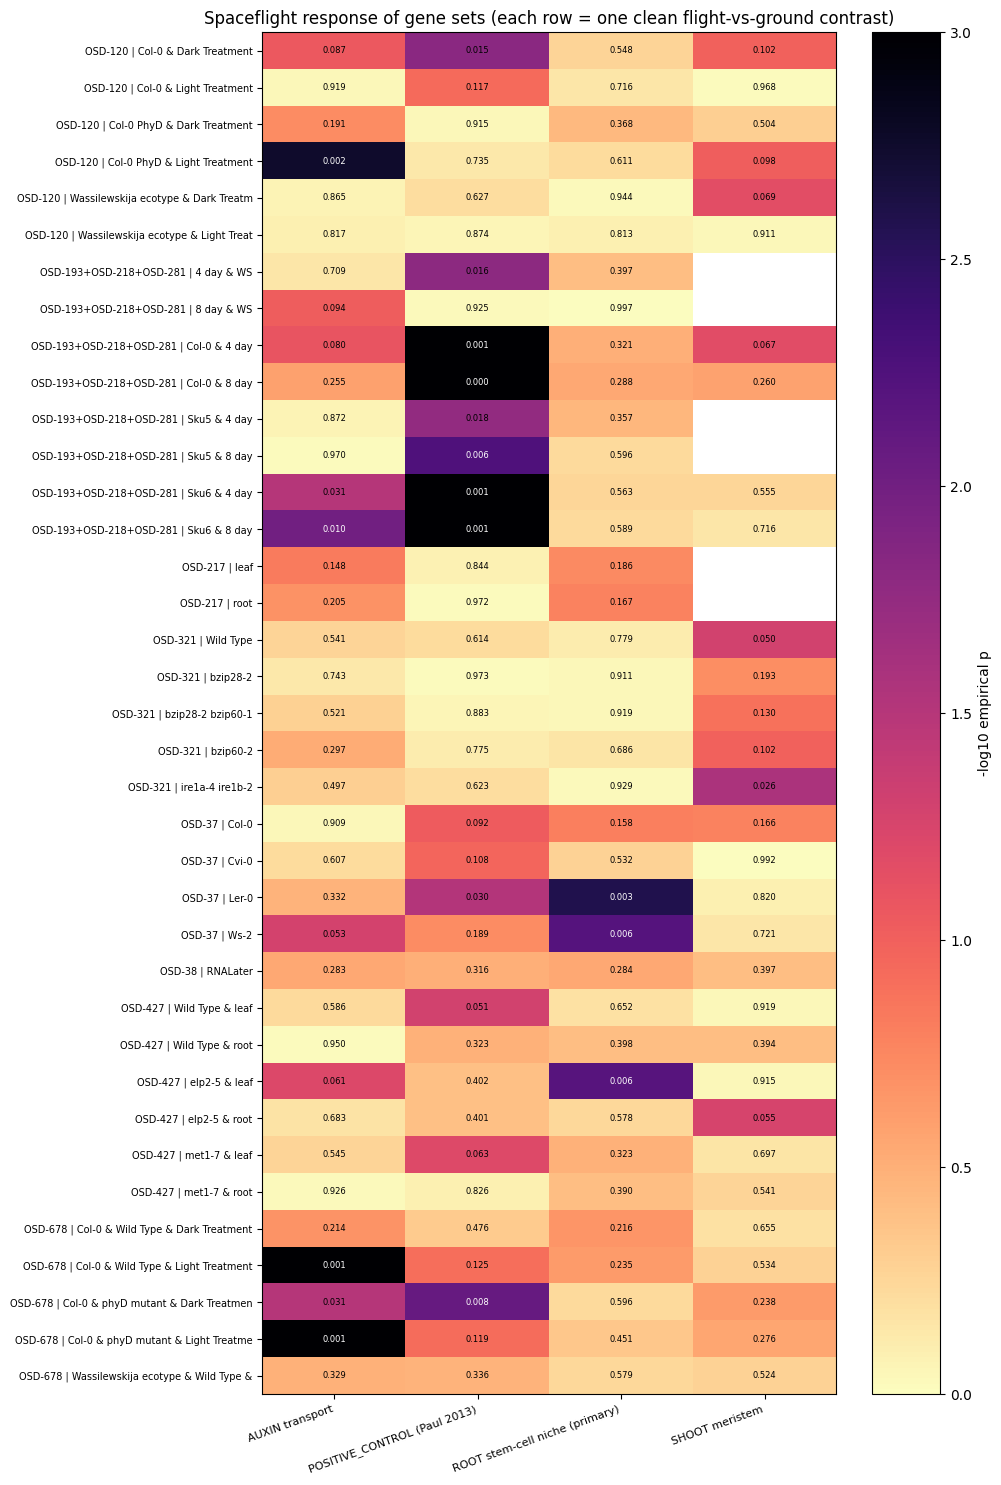

In [9]:
import matplotlib.pyplot as plt
P = R.dropna(subset=['p']).copy(); P['lab'] = P.experiment + ' | ' + P.contrast.str[:35]
M = P.pivot_table(index='lab', columns='set', values='p')
fig, ax = plt.subplots(figsize=(10, 0.35 * len(M) + 2))
im = ax.imshow(-np.log10(M.values), aspect='auto', cmap='magma_r', vmin=0, vmax=3)
ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=20, ha='right', fontsize=8)
ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=7)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]
        if np.isfinite(v): ax.text(j, i, f'{v:.3f}', ha='center', va='center', fontsize=6, color='white' if v < 0.01 else 'black')
plt.colorbar(im, label='-log10 empirical p'); ax.set_title('Spaceflight response of gene sets (each row = one clean flight-vs-ground contrast)')
plt.tight_layout(); plt.savefig('space_meristem_heatmap.png', dpi=150); plt.show()

## How to read the result
- **Positive control first.** If DDF1/DREB2A/TCH4/JAZ7/ELIP1 do not stand out, the data or method cannot be trusted for the other sets.
- **RESPONDS** means the set changes more than random genes of similar expression in ≥ 2 independent studies.
- **NO CONSISTENT RESPONSE** is a real, reportable result: plant stem-cell regulators may be buffered against spaceflight.
- OSD-120 and OSD-678 share the same design (APEX-03: Col-0, phyD, WS; light/dark). Treat agreement between them with care.
- Whole roots or seedlings dilute the meristem signal (the stem-cell niche is a few dozen cells), so a null here is not proof that meristems are unaffected.

In [10]:
print('=' * 70); print('SEND THIS TO CLAUDE'); print('=' * 70); print('\n'.join(REPORT)); print('=' * 70)

SEND THIS TO CLAUDE
OSDR search: 64 Arabidopsis records; 18 RNA-seq studies with a Spaceflight factor
studies with a processed DE table: 14 -> ['OSD-37', 'OSD-38', 'OSD-120', 'OSD-193', 'OSD-217', 'OSD-218', 'OSD-251', 'OSD-281', 'OSD-314', 'OSD-321', 'OSD-346', 'OSD-427', 'OSD-437', 'OSD-678']
clean contrasts in total: 42 across 10 studies
  same data: OSD-193 [Col-0 & 4 day] ~ OSD-218 [4 day & Col-0]  r = 0.969
  same data: OSD-193 [Col-0 & 8 day] ~ OSD-218 [8 day & Col-0]  r = 0.935
  same data: OSD-218 [4 day & WS] ~ OSD-281 [WS & 4 day]  r = 0.979
  same data: OSD-218 [8 day & WS] ~ OSD-281 [WS & 8 day]  r = 0.952
after removing 4 duplicate contrasts: 38 contrasts in 8 independent experiments
SET SUMMARY:
                           set  contrasts  contrasts_p05 experiments_responding                   which                verdict
  POSITIVE_CONTROL (Paul 2013)         38             11                    1/8 OSD-193+OSD-218+OSD-281 NO CONSISTENT RESPONSE
ROOT stem-cell niche (prim